In [1]:
import s3fs
import numpy as np
import zarr

BUCKET = "simulations"
DS = "flow_export/A1"

fs = s3fs.S3FileSystem(profile='default', client_kwargs={'endpoint_url':'http://localhost:8333'})
def _axis(n):
    return np.asarray(zarr.open_array(
        store=s3fs.S3Map(root=f"{BUCKET}/{DS}/channel.zarr/{n}", s3=fs),
        mode="r",
    ))
x, y, z = _axis("x"), _axis("y"), _axis("z")
za = zarr.open_array(
    store=s3fs.S3Map(root=f"{BUCKET}/{DS}/data.zarr", s3=fs),
    mode="r",
)


In [2]:
za

<zarr.core.Array (4001, 5, 128, 129, 128) float32 read-only>

In [3]:
data = za[400::100]

In [4]:
nx = len(x)
dx = x[1] - x[0]
kx = np.fft.fftfreq(nx, dx) * 2 * np.pi
nz = len(z)
dz = z[1] - z[0]
kz = np.fft.fftfreq(nz, dz) * 2 * np.pi

In [5]:
data_hat = np.fft.fftn(data, axes=(2, 4))

In [10]:
energy = (abs(data_hat) ** 2).real

In [11]:
energy_tavg = energy.mean(0)

In [12]:
energy_tavg.shape

(5, 128, 129, 128)

/tmp/ipykernel_924824/1642321122.py:5: UserWarning: Attempting to set identical low and high xlims makes transformation singular; automatically expanding.
  plt.imshow(


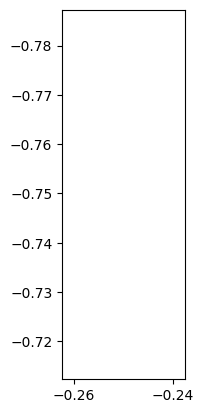

In [21]:
import matplotlib.pyplot as plt
Lx = nx * dx
Lz = nz * dz
dkx, dkz = 2 * np.pi / Lx, 2 * np.pi / Lz
plt.imshow(
    np.fft.fftshift(energy_tavg[0, :, 0, :]).T,
    extent=(kx[0] - dkx/2, kx[-1] + dkx/2,
            kz[0] - dkz/2, kz[-1] + dkz/2),
)
plt.show()

In [19]:
Lz

np.float64(4.19)